# Titanic Data Workflow

**Name:** Christian

**Dataset:** Titanic (seaborn-data copy, titanic.csv)

This project builds a reproducible data workflow in Python: loading, cleaning, exploring and visualizing the Titanic passenger dataset. The goal is to understand which passenger characteristics were associated with survival. It also practices modular code, documentation and Git version control.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Data Ingestion

In [2]:
df = pd.read_csv("titanic.csv")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 3. Data Cleaning

Before cleaning, I check how much data is missing in each column.

In [3]:
print(df.isna().sum())
print('Rows, columns:', df.shape)

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64
Rows, columns: (891, 15)


In [4]:
def standardize_columns(data):
    """Standardize text values and remove a redundant column.

    Strips whitespace and lowercases every text column so category labels
    are consistent, and drops 'alive', which duplicates the 'survived'
    column. Returns a new DataFrame; the input is not modified.
    """
    data = data.copy()
    data.columns = data.columns.str.strip().str.lower()
    for col in data.columns:
        if pd.api.types.is_string_dtype(data[col]) or data[col].dtype == object:
            data[col] = data[col].str.strip().str.lower()
    return data.drop(columns=["alive"], errors="ignore")


def handle_missing_values(data):
    """Handle missing values in the Titanic dataset.

    - age: filled with the median age of passengers who share the same
      sex and passenger class (more realistic than one global median).
    - embarked / embark_town: the 2 missing rows are filled with the mode.
    - deck: dropped, because about 77% of its values are missing.
    Returns a new DataFrame; the input is not modified.
    """
    data = data.copy()
    data["age"] = data["age"].fillna(
        data.groupby(["sex", "pclass"])["age"].transform("median")
    )
    for col in ["embarked", "embark_town"]:
        data[col] = data[col].fillna(data[col].mode()[0])
    return data.drop(columns=["deck"], errors="ignore")


df_clean = handle_missing_values(standardize_columns(df))
print(df_clean.isna().sum())
print('Rows, columns:', df_clean.shape)
df_clean.head()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alone          0
dtype: int64
Rows, columns: (891, 13)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alone
0,0,3,male,22.0,1,0,7.2500,s,third,man,True,southampton,False
1,1,1,female,38.0,1,0,71.2833,c,first,woman,False,cherbourg,False
2,1,3,female,26.0,0,0,7.9250,s,third,woman,False,southampton,True
3,1,1,female,35.0,1,0,53.1000,s,first,woman,False,southampton,False
4,0,3,male,35.0,0,0,8.0500,s,third,man,True,southampton,True


### Cleaning Justification

- **Why clean at all:** Missing values break many calculations and can silently distort averages and plots. The `age` column had 177 missing values (about 20%), `embarked` and `embark_town` had 2 each, and `deck` was missing for about 77% of passengers.
- **Age:** I filled missing ages with the median for the passenger's sex and class instead of dropping rows, so I keep all 891 passengers and avoid losing a large share of the data. The median is used because it is less affected by outliers than the mean.
- **Embarked:** Only 2 values were missing, so filling with the most common port is a very small assumption.
- **Deck:** With about 77% missing, any fill would be mostly invented, so I dropped the column.
- **Standardizing text:** Lowercasing and stripping whitespace prevents the same category from being counted as two different labels. I dropped `alive` because it duplicates `survived`.
- **Not removed:** I kept extreme `fare` values because they are real first-class tickets, not errors.

## 4. Exploratory Data Analysis (EDA)

The function below groups the cleaned data by a category and reports the number of passengers and the survival rate for each group. I use it to compare survival across sex, passenger class and age group before plotting.

In [5]:
def survival_summary(data, group_cols):
    """Summarize survival by one or more grouping columns.

    Parameters
    ----------
    data : DataFrame
        The cleaned Titanic data (must contain a 'survived' column).
    group_cols : str or list of str
        Column name(s) to group by.

    Returns
    -------
    DataFrame
        One row per group with the passenger count and the survival rate
        (share of passengers who survived), rounded to 3 decimals.
    """
    summary = (
        data.groupby(group_cols, observed=True)["survived"]
        .agg(passengers="count", survival_rate="mean")
        .round(3)
    )
    return summary


# Add an age-group column so age can be compared as categories
df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["child (0-12)", "teen (13-18)", "young adult (19-35)", "adult (36-60)", "senior (61+)"],
)

print("Overall survival rate:", round(df_clean["survived"].mean(), 3))
print()
print(survival_summary(df_clean, "sex"))
print()
print(survival_summary(df_clean, "pclass"))
print()
print(survival_summary(df_clean, "age_group"))
print()
print(survival_summary(df_clean, ["pclass", "sex"]))

Overall survival rate: 0.384

        passengers  survival_rate
sex                              
female         314          0.742
male           577          0.189

        passengers  survival_rate
pclass                           
1              216          0.630
2              184          0.473
3              491          0.242

                     passengers  survival_rate
age_group                                     
child (0-12)                 69          0.580
teen (13-18)                 70          0.429
young adult (19-35)         514          0.358
adult (36-60)               216          0.384
senior (61+)                 22          0.227

               passengers  survival_rate
pclass sex                              
1      female          94          0.968
       male           122          0.369
2      female          76          0.921
       male           108          0.157
3      female         144          0.500
       male           347          0.135


In [6]:
def correlation_check(data, columns):
    """Return the correlation matrix for the chosen numeric columns.

    Values close to +1 or -1 indicate a strong linear relationship and
    values close to 0 indicate little linear relationship. Correlation
    does not show cause and effect.
    """
    return data[columns].corr().round(2)


numeric_cols = ["survived", "pclass", "age", "fare", "sibsp", "parch"]
print(correlation_check(df_clean, numeric_cols))

          survived  pclass   age  fare  sibsp  parch
survived      1.00   -0.34 -0.06  0.26  -0.04   0.08
pclass       -0.34    1.00 -0.41 -0.55   0.08   0.02
age          -0.06   -0.41  1.00  0.12  -0.25  -0.18
fare          0.26   -0.55  0.12  1.00   0.16   0.22
sibsp        -0.04    0.08 -0.25  0.16   1.00   0.41
parch         0.08    0.02 -0.18  0.22   0.41   1.00


### EDA Findings

- About 38% of passengers survived overall.
- Women survived at roughly 74% and men at about 19%, so sex is the biggest difference in the data.
- Survival falls as class gets lower: about 63% in first class, 47% in second class and 24% in third class.
- The correlation table agrees: `survived` has a moderate negative correlation with `pclass` (-0.34) and a weaker positive one with `fare` (0.26). Age has almost no linear relationship with survival (-0.06), but the age-group table shows that children survived more often (58%) than other groups.

## 5. Visualizations

Each chart has a title and labeled axes, followed by a short interpretation.

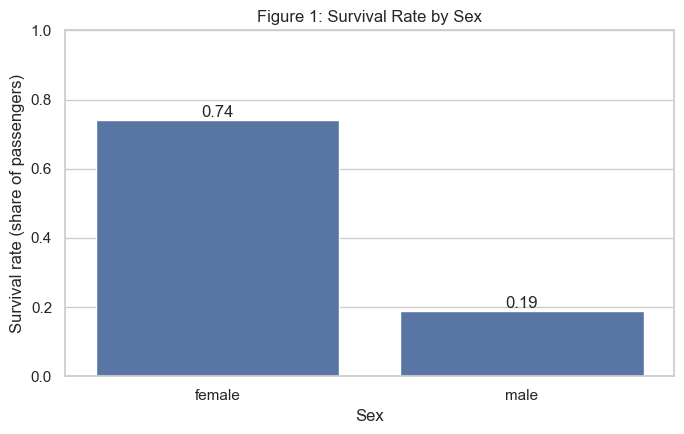

In [7]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 4.5))
ax = sns.barplot(data=df_clean, x="sex", y="survived", order=["female", "male"], errorbar=None)
ax.set_title("Figure 1: Survival Rate by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Survival rate (share of passengers)")
ax.set_ylim(0, 1)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")
plt.tight_layout()
plt.show()

**Interpretation (Figure 1):** Women survived at about 74% and men at about 19%. This is the largest gap in the dataset and fits the "women and children first" evacuation practice, although the data alone cannot prove why the gap exists.

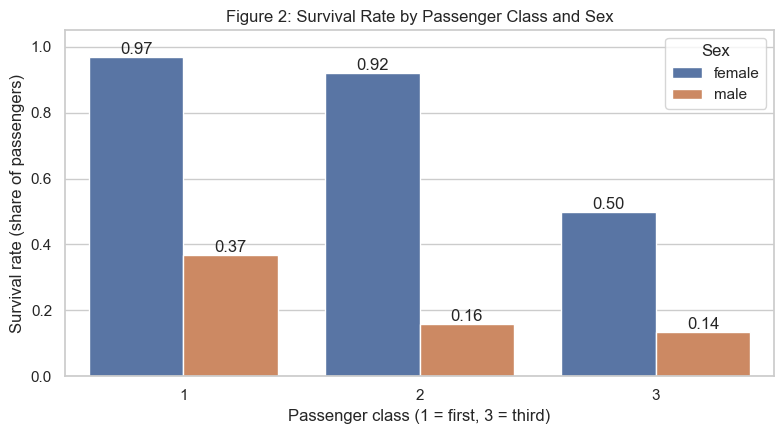

In [8]:
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(
    data=df_clean, x="pclass", y="survived", hue="sex",
    hue_order=["female", "male"], errorbar=None,
)
ax.set_title("Figure 2: Survival Rate by Passenger Class and Sex")
ax.set_xlabel("Passenger class (1 = first, 3 = third)")
ax.set_ylabel("Survival rate (share of passengers)")
ax.set_ylim(0, 1.05)
ax.legend(title="Sex")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")
plt.tight_layout()
plt.show()

**Interpretation (Figure 2):** Survival drops from first to third class for both sexes. Almost all first-class women survived (about 97%), while only about half of third-class women did (50%). Men were far less likely to survive in every class, with the best rate in first class (about 37%). So class and sex both matter, and they should not be read separately.

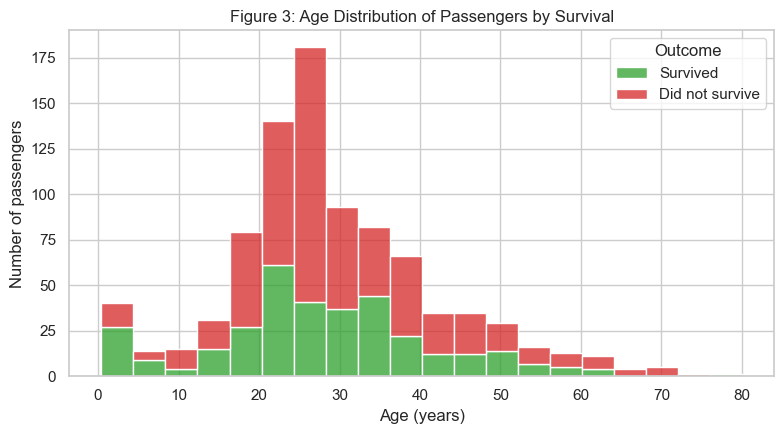

In [9]:
plt.figure(figsize=(8, 4.5))
ax = sns.histplot(
    data=df_clean, x="age", hue="survived", bins=20,
    multiple="stack", palette={0: "tab:red", 1: "tab:green"},
)
ax.set_title("Figure 3: Age Distribution of Passengers by Survival")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of passengers")
ax.legend(title="Outcome", labels=["Survived", "Did not survive"])
plt.tight_layout()
plt.show()

**Interpretation (Figure 3):** Most passengers were between about 20 and 40 years old, and in that range more people did not survive than survived. The youngest bars (under about 10 years) show a larger share of survivors, which matches the 58% survival rate for children in the EDA table. The tall bar near age 25-30 partly comes from filling missing ages with group medians, so that peak is exaggerated.

## 6. Summary and Interpretation

**What I learned:** In this dataset 891 passengers are recorded and about 38% survived. Survival was strongly linked to sex and passenger class. Women were far more likely to survive than men, and first-class passengers were far more likely to survive than third-class passengers. Fare points the same way as class, because higher fares are paid by first-class passengers.

**Interesting patterns:** The combination of sex and class is more informative than either alone. First-class women survived at about 97%, while third-class men survived at about 14%. Children had a higher survival rate (about 58%) than any adult age group, while age on its own had almost no linear correlation with survival.

**Limitations and assumptions:** About 20% of ages were missing, and I filled them with the median age for the same sex and class. This is an assumption, and it shrinks the natural spread of ages and creates a peak near the median values (visible in Figure 3). I dropped `deck` because most values were missing, so I could not study where on the ship passengers were. The dataset is only 891 passengers, so it is a sample and not the full list of people aboard. The patterns I found are associations and do not prove cause and effect. Class, sex, age and fare are related to each other, so I cannot tell how much each one matters on its own.

**Surprising or unclear:** I expected age to show a stronger effect, and it only stands out for young children. I am also unsure how much of the third-class result is caused by where those passengers' cabins were on the ship, because that information is missing from the cleaned data.